# JavaScript Generators


A comprehensive guide to JavaScript generator functions — from core mechanics to async patterns, practical use cases, and production best practices. Generators are a foundational low-level construct that powers iteration, streaming, and async coordination in JavaScript.


## Table of Contents

1. [Module 01: Generator Basics](#module-01-generator-basics)
2. [Module 02: Working with Generator Patterns](#module-02-working-with-generator-patterns)
3. [Module 03: Practical Use Cases for Generators](#module-03-practical-use-cases-for-generators)
4. [Module 04: Best Practices and Production Concerns](#module-04-best-practices-and-production-concerns)


In [1]:
from pathlib import Path
from IPython.display import HTML, display
import base64

def render_diagram(image_path, width=900):
    data = base64.b64encode(Path(image_path).read_bytes()).decode()
    display(HTML(f'<div style="text-align:center"><img src="data:image/png;base64,{data}" width="{width}"/></div>'))

## Module 01: Generator Basics


_Introduces generator functions from first principles: what they are, how they differ from regular functions, and how to write and consume them using `function*`, `yield`, `next()`, and `yield*`._

**Version note:** This material was written using ES2023 (ES14) and is fully applicable from ES2016 (ES7) onwards.


### What Is a Generator?

A **generator** is a special function that can be paused mid-execution and resumed later from exactly the point where it was paused.

- **Pause:** `yield` suspends execution and optionally emits a value
- **Resume:** calling `.next()` on the generator object resumes from the last `yield`

Unlike regular functions (which run to completion once called), generators are driven externally — the caller controls when execution advances.


### Use Cases for Generators

- **Retrieving a series of values** — generators are memory-optimised: only the latest generated value is held in memory, not the entire sequence
- **Streaming data** — yield data chunk by chunk as it arrives
- **Generating values lazily** — nothing is produced unless actively requested
- **Asynchronous programming** — coordinate async operations with synchronous-looking control flow

#### Lazy Evaluation

> Nothing is generated unless it's actively requested. This is great for performance optimisation because it prevents unnecessary computation.

Generators are a **low-level construct** — you won't use them in everyday application code, but they are a fundamental building block. Libraries and frameworks use them internally. Understanding them deepens your understanding of JavaScript's iteration protocol.

**Generators often have alternatives** (a regular `for` loop, an array, `async/await`). Sometimes the generator is best practice; sometimes it's a matter of preference.


### Regular Functions vs. Generator Functions

| | Regular Function | Generator Function |
|---|---|---|
| **Execution** | Run-to-completion — once triggered, runs until done | Pause and resume — runs until the next `yield` |
| **Syntax** | `function foo()` | `function* foo()` |
| **Returns** | A single value | A **generator object** (iterator) |
| **Control** | Caller has no mid-execution control | Caller drives execution via `.next()` |


### Creating and Using Generator Functions

The `function*` keyword declares a generator function. Calling it does **not** execute the body — it returns a **generator object**. Execution begins only on the first `.next()` call.

Three elements needed to execute a generator:
1. The generator **function** (`function* foo()`)
2. The **generator object** (`const gen = foo()`)
3. Calling **`.next()`** on the object to advance execution


```js
// Basic generator — yields each inventory item on demand
function* inventoryGenerator() {
    yield 'Smartphone';
    yield 'Tablet';
    yield 'Laptop';
}

const inventory = inventoryGenerator();
console.log(inventory.next().value); // 'Smartphone'
console.log(inventory.next().value); // 'Tablet'
console.log(inventory.next().value); // 'Laptop'

// Generators are also iterators — usable in for...of and spread
for (const item of inventoryGenerator()) {
    console.log(item);
}

const allItems = [...inventoryGenerator()];
console.log(allItems); // ['Smartphone', 'Tablet', 'Laptop']
```


### The `next()` Return Object

Every `.next()` call returns an object with two properties:

```js
{ value: <yielded value>, done: <boolean> }
```

- `value` — the value passed to `yield` (or `undefined` if none)
- `done` — `false` while the generator has more yields; `true` when the function has returned

You can also **return a value** from a generator using `return`, which sets `done: true` and `value` to the returned value on that final call.

#### Two-Way Communication

You can pass a value **back into** the generator by passing an argument to `.next(val)`. That value becomes the result of the `yield` expression inside the generator body.


### Benefits of Generators

- **Lazy evaluation** — compute only when asked
- **Stateful iteration** — the generator remembers where it left off between calls
- **Control flow** — fine-grained, explicit control over when execution advances


### Cancelling a Generator

A generator can be cancelled in two ways:

1. **`.return(value)`** — terminates the generator immediately, returning `{ value, done: true }`
2. **`.throw(error)`** — injects an error at the current suspension point

**Use cases for cancellation:**
- Resource management
- Long-running task termination
- User interactions (e.g. user cancels an operation)
- Error handling
- Async flow control


```js
function* inventoryGenerator() {
    yield 'Smartphone';
    yield 'Tablet';
    return 'Laptop';
}

// Cancelling with .return()
const gen1 = inventoryGenerator();
console.log(gen1.return(12));  // { value: 12, done: true }
console.log(gen1.next());     // { value: undefined, done: true }

// Cancelling with .throw()
const gen2 = inventoryGenerator();
try {
    gen2.throw('Oops');
} catch (error) {
    console.log('Error:', error);   // 'Oops'
    console.log(gen2.next());       // { value: undefined, done: true }
}
```


### Generator Delegation with `yield*`

`yield*` delegates to another generator (or any iterable), yielding all its values before continuing.

**Why use delegation?**
- **Composition** — combine multiple smaller generators into one larger pipeline
- **Iterable flattening** — work with nested iterables while keeping code readable


```js
function* regularOrderGenerator() {
    yield 'Order #1001';
    yield 'Order #1002';
}

function* expressOrderGenerator() {
    yield 'Order #1003';
    yield 'Order #1004';
}

function* orderProcessingGenerator() {
    yield* regularOrderGenerator();  // delegates — yields all regular orders first
    yield* expressOrderGenerator();  // then all express orders
}

const orderProcessing = orderProcessingGenerator();
console.log(orderProcessing.next().value); // 'Order #1001'
console.log(orderProcessing.next().value); // 'Order #1002'
console.log(orderProcessing.next().value); // 'Order #1003'
console.log(orderProcessing.next().value); // 'Order #1004'
```


### Demo: Generator Basics

Hands-on examples covering: basic generator with `next()`, iteration with `for...of` and spread, the `next()` return object, feedback via `next(value)`, cancellation with `.return()` and `.throw()`, and `yield*` delegation.

See [`01-generator-basics-demos/`](01-generator-basics-demos/) for the full project.


### Summary

- A generator function (`function*`) returns a generator object when called
- `yield` pauses execution and emits a value; `.next()` resumes it
- Every `.next()` returns `{ value, done }`
- Generators are iterators — compatible with `for...of`, spread, and destructuring
- Key uses: lazy evaluation, memory-efficient series, streaming, async coordination
- `.return()` and `.throw()` allow external cancellation
- `yield*` delegates to another generator or iterable


## Module 02: Working with Generator Patterns


_Covers how generators combine with `async/await` and Promises, how to handle errors inside generators, and where generators appear in enterprise frameworks like Redux Saga._

These are not traditional design patterns — they are combinations of common coding constructs with generators.


### Generators vs. Async/Await

| | Generators | Async/Await |
|---|---|---|
| **Nature** | Functions that pause and resume | Async functions awaitable with `await` |
| **Async?** | Not necessarily, but can handle async code | Always returns a Promise |
| **Async syntax** | `yield` a promise; external mechanism resumes | `await` pauses until resolved |
| **Best for** | Complex iteration, incremental processing, fine-grained control | Most async workflows — simpler and more readable |

They can be used as **alternatives** (often `async/await` is enough) or as **complements** (combining them unlocks incremental, memory-efficient async processing).

**Async/await characteristics:**
- Simplifies working with Promises
- Makes async code look synchronous
- `await` pauses until the Promise resolves
- Great for sequential async operations

**Generator characteristics:**
- Yield multiple values over time
- Not necessarily async, but can yield Promises
- Useful for complex iteration, lazy evaluation, streaming


### When to Reach for Generators

**Large dataset — customer records:**
- Too large to load into memory at once
- Needs pre-processing before use
- Generator reads in chunks, pauses after each chunk, performs complex operations, memory-friendly
- Processes data on the fly — before the entire dataset is available

**Real-time financial data (infinite stream):**
- Continuous, potentially infinite — can't store it all
- Generator yields each incoming data point just-in-time
- Evaluates and displays information on demand, no pre-loading

**Paginated API:**
- Loading all products at once would be inefficient
- `async/await` inside a generator provides synchronous-looking control flow
- Yields each product as it becomes available, enabling incremental processing


### Async Generators

An **async generator** combines `async function*` — it can `await` Promises inside and `yield` values incrementally. Consumed with `for await...of`.

**Why not just `async/await`?**
- Higher level of control over incremental processing
- Process data in chunks without loading the entire set into memory at once


```js
// Async generator streaming a paginated API
async function* productStream() {
    let nextPageUrl = '/api/products?page=1';
    while (nextPageUrl) {
        const response = await fetch(nextPageUrl);
        const data = await response.json();
        nextPageUrl = data.nextPageUrl;
        for (const product of data.products) {
            yield product; // yield each product as it arrives
        }
    }
}

// IIFE (Immediately Invoked Function Expression) — runs the async loop
(async () => {
    for await (const product of productStream()) {
        displayProduct(product); // process each product incrementally
    }
})();
```


### Error Handling in Generators

Generators can handle errors gracefully. There are two placement strategies:

1. **`try/catch` outside the generator** — catches unhandled errors from the caller side, prevents crashes
2. **`try/catch` inside the generator** — generally preferred; the generator itself handles the error, yields an error message that can be logged or handled downstream, and continues execution

Handling inside is better because it keeps the error management co-located with the code that can produce it.


```js
// Error handling inside the generator
function* errorProneGenerator() {
    try {
        yield 'Start Inventory Check';
        throw new Error('Oops, scanner malfunction!');
    } catch (error) {
        yield `Error: ${error.message}`; // yields the error message instead of crashing
    }
    yield 'End inventory check';
}

for (const item of errorProneGenerator()) {
    console.log('item:', item);
}
// 'Start Inventory Check'
// 'Error: Oops, scanner malfunction!'
// 'End inventory check'
```


### Generators in Enterprise Frameworks

Generators are often replaced by `async/await` in modern code, but they remain a crucial low-level construct for certain use cases — especially streams. Some packages still **require** generator functions.

**Redux Saga** is a prominent example:
- Modern JS library built on generator functions
- Manages side effects in Redux applications
- Generators make complex async flows easy to follow and test

Redux Saga capabilities:
- Cancellation of running effects
- Parallel execution
- Easy testing (effects are plain objects, not actual calls)
- Straightforward complex side-effect handling


### Generators and Promises

Before `async/await`, **yielding Promises from generators** was the preferred pattern for synchronous-looking async code. Understanding it is useful for reading legacy codebases.

The pattern: a generator yields a Promise → an external runner resolves the Promise → then calls `.next(resolvedValue)` to resume the generator.

**Benefits of this pattern:**
- Higher code readability
- Fine-grained control over execution flow
- Simplified error handling

**Generator vs. Promise chain trade-offs:**

| Generator | Promise Chain |
|---|---|
| Control | Simplicity |
| Flexibility | Less boilerplate |
| Error handling | Wide support |



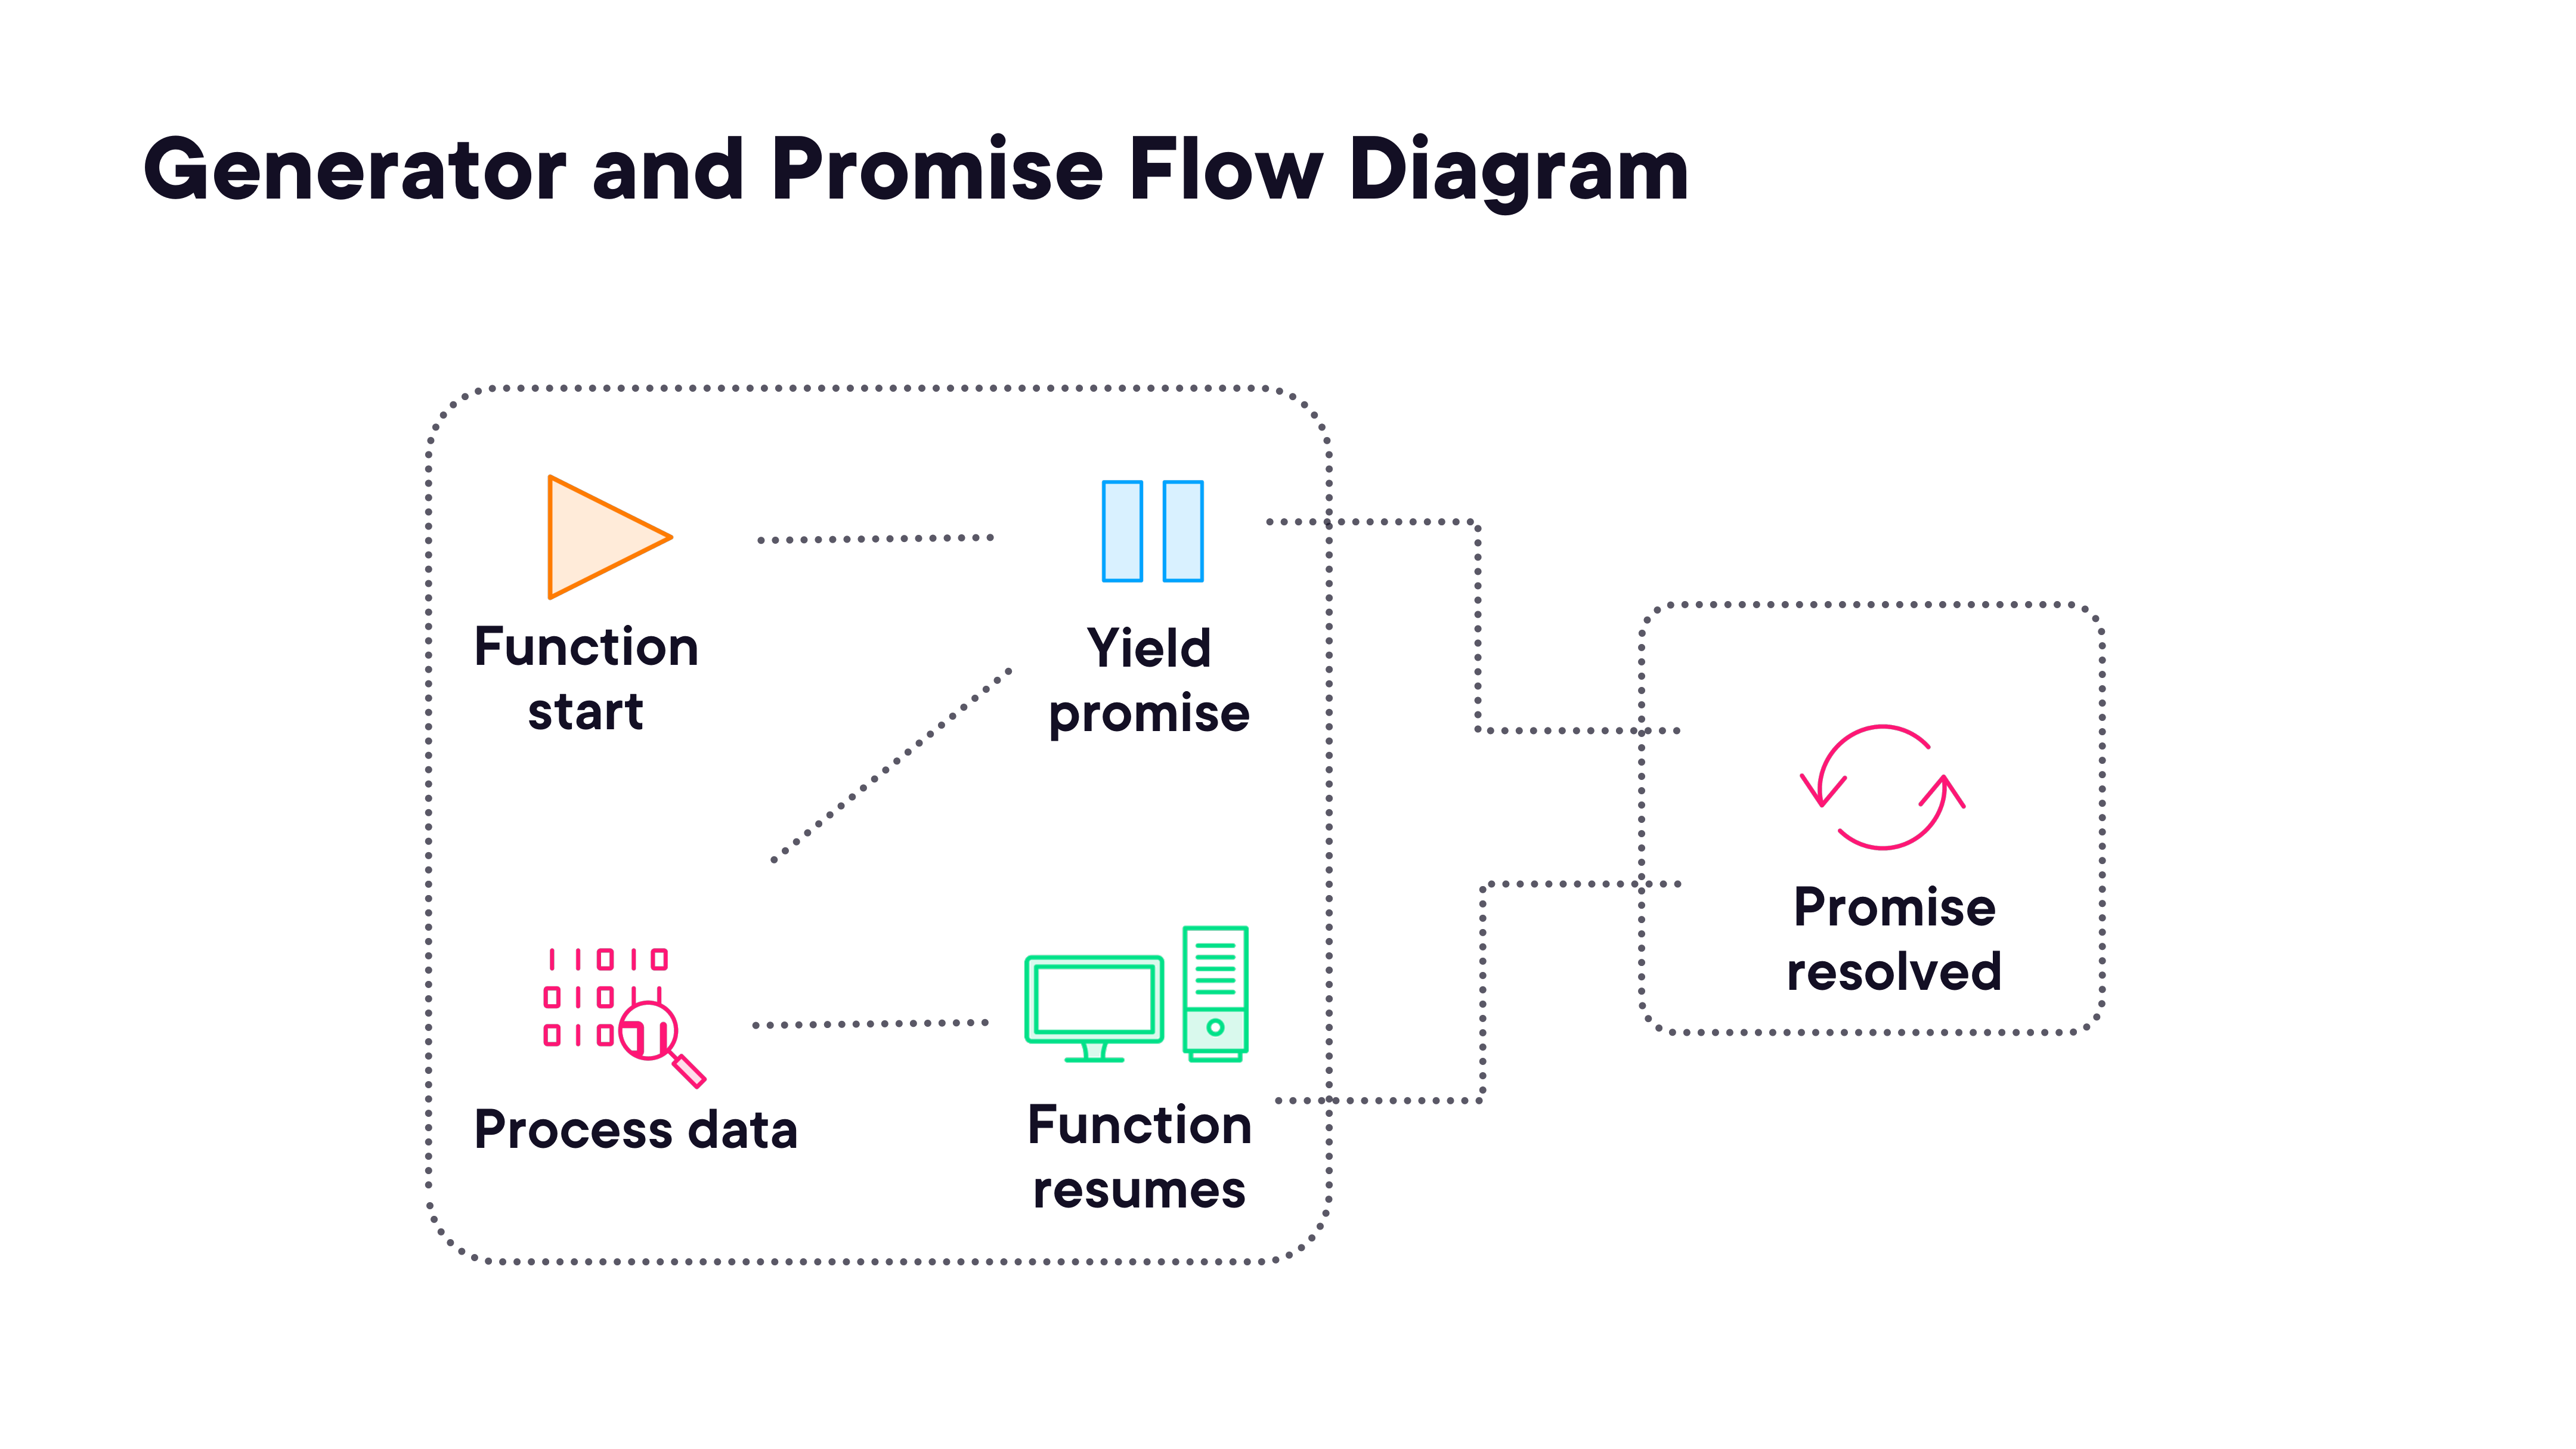

In [2]:
render_diagram(Path('assets/01-generator-promise-flow.png'))

```js
// Yielding promises in a generator (pre-async/await pattern)
function* stockUpdateGenerator() {
    yield updateStock('Electronics');
    yield updateStock('Books');
    yield updateStock('Clothing');
}

function updateStock(category) {
    return new Promise(resolve => {
        setTimeout(() => {
            console.log(`${category} stock updated`);
            resolve();
        }, 1000);
    });
}

// External iterator manually threads the promises
const stockUpdater = stockUpdateGenerator();
stockUpdater.next().value.then(() => {
    stockUpdater.next().value.then(() => {
        stockUpdater.next();
    });
});
```


### Demo: Generator Patterns

Examples covering: async generators with paginated APIs, error handling inside generators, yielding Promises with an external iterator runner, and a comparison implementation without generators.

See [`02-generator-patterns-demos/`](02-generator-patterns-demos/) for the full project.


### Summary

- Generators and `async/await` are both alternatives and complements — choose based on the need for incremental control
- `async function*` creates an async generator consumable with `for await...of`
- Handle errors **inside** the generator with `try/catch` for clean, self-contained error management
- Redux Saga uses generators to make complex async side effects testable and cancellable
- Yielding Promises + external runner was the pre-`async/await` pattern for sync-looking async code


## Module 03: Practical Use Cases for Generators


_Deep-dives into concrete scenarios where generators shine: lazy evaluation, data pagination, data streaming, database/API integration, and design patterns (observer and mediator)._

Generators are the right tool when there is a lot of data, memory needs to be managed, and iteration is required.


### Lazy Evaluation

Generators are lazy by nature — values are computed **on demand**, not upfront.

**Benefits:**
- Reduces initial load time
- Reduces memory footprint
- Avoids unnecessary computation

**Practical example:** A Node/Express endpoint that processes a large product dataset. Instead of loading everything from the database up front, a generator processes the dataset chunk by chunk and yields products on demand as the user scrolls. Batching the data in memory is preferable to making repeated database calls (each of which carries significant overhead).


### Data Streaming

Streaming is close to the core nature of generators.

- Dealing with data in chunks
- Lazy evaluation
- Memory optimisation

**Typical streaming pipeline:**

1. Receive the bytes
2. Convert the bytes
3. Yield the result

**What to do with yielded data:**
- Display on the website
- Write to a file
- Write to a database

**Example:** A WebSocket streaming stock data or a social media feed. The stream is continuous and potentially infinite — you can't store it all. A generator yields each incoming data point just-in-time, allowing the application to display or process it immediately without pre-loading.


### Generators with Databases and APIs

Generators are useful for big datasets — retrieving and processing records chunk by chunk.

**Typical database pattern:**
1. Fetch results in batches (ensures the result set fits in memory)
2. Process each batch
3. Write results (e.g. to a CSV file)

This avoids loading an entire large result set into memory at once.


### Design Patterns with Generators

Generators can be integrated into classical OOP patterns to add a layer of control and sequence management.

#### Observer Pattern

- A **Subject** maintains a list of **Observers**
- The Subject notifies observers of state changes
- Commonly used in event handling systems

A generator can be the `notify()` method — yielding each observer notification one at a time, giving the caller control over when each observer is invoked.

#### Mediator Pattern

- Controls and manages communication between different objects
- Objects communicate through a central Mediator instead of referencing each other directly
- Reduces coupling between components

A generator can power the Mediator's `communicate()` method — yielding each component's response in sequence.

**Why add generators to these patterns?**
- Add a layer of control and flexibility
- Manage the sequence of operations precisely


```js
// Observer Pattern with generator-based notification
class Subject {
    constructor() { this.observers = []; }

    addObserver(observer) { this.observers.push(observer); }

    *notify() {
        for (const observer of this.observers) {
            yield observer.update(); // caller controls when each observer is notified
        }
    }
}

class Observer {
    constructor(name) { this.name = name; }
    update() { console.log(`${this.name} is notified.`); }
}

const subject = new Subject();
subject.addObserver(new Observer('Observer 1'));
subject.addObserver(new Observer('Observer 2'));

for (const notification of subject.notify()) {
    // process each notification one at a time
}
```


```js
// Mediator Pattern with generator-based communication
class Mediator {
    constructor() { this.components = []; }

    addComponent(component) {
        this.components.push(component);
        component.setMediator(this);
    }

    *communicate(initiator) {
        for (const component of this.components) {
            if (component !== initiator) {
                yield component.receive(); // yield each component's response
            }
        }
    }
}

class Component {
    constructor(name) { this.name = name; this.mediator = null; }
    setMediator(mediator) { this.mediator = mediator; }
    send() {
        console.log(`${this.name} sends a message`);
        for (const msg of this.mediator.communicate(this)) { /* process */ }
    }
    receive() { console.log(`${this.name} received a message`); }
}

const mediator = new Mediator();
mediator.addComponent(new Component('Component 1'));
mediator.addComponent(new Component('Component 2'));
mediator.components[0].send();
```


### Demo: Practical Use Cases

Full project examples covering: a Node/Express lazy-loading product endpoint with scroll pagination, a WebSocket streaming demo, a database batch-processing demo that writes to CSV, the Observer Pattern with generators, and the Mediator Pattern with generators.

See [`03-practical-use-cases-demos/`](03-practical-use-cases-demos/) for the full project.


### Summary

- Generators are ideal for large data, memory-sensitive, and iteration-heavy scenarios
- **Lazy evaluation** — compute on demand; reduces load time and memory footprint
- **Data streaming** — yield chunks as they arrive; handle potentially infinite streams
- **Database/API integration** — fetch in batches to keep memory usage bounded
- **Design patterns** — generators augment Observer and Mediator patterns with sequential control


## Module 04: Best Practices and Production Concerns


_Covers debugging generator state and errors, performance profiling, optimisation techniques and pitfalls, and security considerations._


### Debugging Generators

Debugging generators is similar to debugging other JavaScript code but is made more challenging by their pause/resume execution model.

**Common bugs:**
- **Internal state issues** — bugs arising from state that is not managed or fully understood. Be careful with external state that is crucial to the generator's inner state.
- **Unhandled errors thrown inside the generator** — can lead to unexpected, difficult-to-trace outcomes

**Best practice:** Always wrap generator body code in `try/catch`. Errors that propagate out of a generator are tricky to debug; catching them inside keeps the failure localised.

**Tools:** `console.log` for state inspection, Chrome DevTools for step-through debugging of the generator's execution.


```js
// Bug: error propagates uncaught
function* errorProneGenerator() {
    yield 'All good!';
    throw new Error('Oops!');
}

const errorGen = errorProneGenerator();
console.log(errorGen.next().value); // 'All good!'
// errorGen.next().value — throws, hard to debug

// Fix: catch inside the generator
function* safeGenerator() {
    try {
        yield 'All good!';
        throw new Error('Oops!');
    } catch (e) {
        yield `Caught: ${e.message}`;
    }
}
```


### Performance Profiling

Profiling measures:
- **Execution time**
- **Memory usage**
- **Bottleneck identification**

**Profiling approach:**
1. Measure time with `console.time()` / `console.timeEnd()`
2. Use Chrome DevTools for detailed memory and CPU analysis
3. Identify code locations where memory spikes — these are the bottlenecks. For generators, the bottleneck could be the generator itself or the code processing the yielded values.

**Iterative optimisation process:**

1. **Profile** — measure current behaviour
2. **Optimise** — rewrite bottleneck code, use more efficient algorithms, optimise processing of yielded data; try without a generator if possible
3. **Retest** — re-run the profiler to verify improvement

> Speed is just one part — memory efficiency matters equally.


```js
function* largeDataSetGenerator(size) {
    for (let i = 0; i < size; i++) {
        yield i;
    }
}

function processItem(item) {
    return item ** item;
}

// Measuring generator performance
const dataSetGen = largeDataSetGenerator(1_000_000);

console.time('Generator Performance');
let sum = 0;
for (const num of dataSetGen) {
    sum += processItem(num);
}
console.timeEnd('Generator Performance');
```


### Performance Optimisation Tips

**Techniques:**
- **Memory management** — generators are typically memory-efficient; yield smaller chunks. But find the balance: API and database calls are heavy on performance, so chunking has a cost too.
- **Lazy evaluation** — strong point of generators; reduce initial load time, reduce memory footprint, avoid unnecessary computations
- **Asynchronous operations** — for complex async situations, generators can handle enormous amounts of data with more control than nested callbacks or promise chains

**Pitfalls:**

- **Don't overuse generators** — whenever a simpler solution (loop, array, `async/await`) is available, prefer it. Generators add complexity.
- **Don't use generators for small datasets** — generators don't add meaningful overhead (they typically yield results from DB/API calls which are the heavy part), but for small datasets they're unnecessary complexity.
- **Be cautious of infinite loops** — an infinite generator without a termination condition will never complete

**Generator Pitfalls summary:**
- Don't overuse generators
- Don't use generators for small datasets
- Be cautious of infinite loops

**Choosing the best solution:** Profile your code with and without a generator to see what it does to performance. Assess the requirement, consider possible solutions, and choose the cleanest and highest-performing one.


### Best Practices

- **Testing** — test generator functions just like any other function; test individual yield outputs and error paths
- **Documentation** — document what a generator yields and under what conditions it terminates
- **Keep It Simple (KISS)** — use a generator only when its unique capabilities are actually needed


### Security and Generators

Generators are not inherently dangerous or insecure. However, the same security considerations that apply to any code construct apply here:

**Injection attacks:**
- Not generator-specific
- Possible when generators interact with databases or external APIs
- Validate and sanitise user inputs; use prepared statements

**Denial of Service (DoS):**
- Risk in the context of large datasets, intensive computations, or long-running processes
- Generators processing unbounded input could be exploited
- Implement and enforce resource limits; monitor resource usage

**State management and side effects:**
- Generators maintain state across yields
- That state could include sensitive data
- Carefully manage state to avoid unintended side effects

> Like any code construct, security best practices must be applied to reduce risks.


### Demo: Best Practices and Production Concerns

Examples covering: debugging generator state problems and thrown errors, profiling generator performance with `console.time()` and DevTools, and applying fixes step by step.

See [`04-best-practices-demos/`](04-best-practices-demos/) for the full project.


### Summary

- Debug generators by inspecting state at each yield and always using `try/catch` inside the generator body
- Profile with `console.time()` for quick measurements, DevTools for detailed memory/CPU analysis
- Optimise iteratively: profile → optimise → retest
- Avoid overuse: prefer simpler constructs when the generator's unique capabilities (lazy, stateful, cancellable) are not needed
- Apply standard security practices: input validation, resource limits, careful state management
